step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully")

Libraries Imported Successfully


Task 1: Load the Dataset

In [2]:
import pandas as pd
df = pd.read_csv("zomato.csv")
df = df.drop(['Unnamed: 0', 'Unnamed: 0.1'], axis=1)
df.head()

,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


Task 2: Dataset Shape

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7105, 10)


Task 3: Dataset Information

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7105 entries, 0 to 7104
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   restaurant name        7105 non-null   str    
 1   restaurant type        7105 non-null   str    
 2   rate (out of 5)        7037 non-null   float64
 3   num of ratings         7105 non-null   int64  
 4   avg cost (two people)  7048 non-null   float64
 5   online_order           7105 non-null   str    
 6   table booking          7105 non-null   str    
 7   cuisines type          7105 non-null   str    
 8   area                   7105 non-null   str    
 9   local address          7105 non-null   str    
dtypes: float64(2), int64(1), str(7)
memory usage: 555.2 KB


Task 4: Missing Values Analysis

In [5]:
print(df.isnull().sum())

restaurant name           0
restaurant type           0
rate (out of 5)          68
num of ratings            0
avg cost (two people)    57
online_order              0
table booking             0
cuisines type             0
area                      0
local address             0
dtype: int64


Task 5: Handle Missing Values

In [6]:
df['cuisines type'].fillna("Unknown", inplace=True)

df['rate (out of 5)'].fillna(df['rate (out of 5)'].mode()[0], inplace=True)

df['avg cost (two people)'].fillna(df['avg cost (two people)'].median(), inplace=True)

print("Missing values successfully handled.")

Missing values successfully handled.


C:\Users\sahil\AppData\Local\Temp\ipykernel_17568\852924813.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['cuisines type'].fillna("Unknown", inplace=True)
C:\Users\sahil\AppData\Local\Temp\ipykernel_17568\852924813.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignmen

Task 6: Quantitative and Qualitative Data

In [7]:
quantitative = df.select_dtypes(include=['int64','float64'])
qualitative = df.select_dtypes(include=['object'])

print("Quantitative Columns:", quantitative.columns)
print("Qualitative Columns:", qualitative.columns)

Quantitative Columns: Index(['rate (out of 5)', 'num of ratings', 'avg cost (two people)'], dtype='str')
Qualitative Columns: Index(['restaurant name', 'restaurant type', 'online_order', 'table booking',
       'cuisines type', 'area', 'local address'],
      dtype='str')


C:\Users\sahil\AppData\Local\Temp\ipykernel_17568\3010784752.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  qualitative = df.select_dtypes(include=['object'])


Task 7: Descriptive Statistics

In [8]:
print(df.describe())

       rate (out of 5)  num of ratings  avg cost (two people)
count      7037.000000     7105.000000            7048.000000
mean          3.514253      188.921042             540.286464
std           0.463249      592.171049             462.902305
min           1.800000        1.000000              40.000000
25%           3.200000       16.000000             300.000000
50%           3.500000       40.000000             400.000000
75%           3.800000      128.000000             600.000000
max           4.900000    16345.000000            6000.000000


Task 8: Online Order Availability

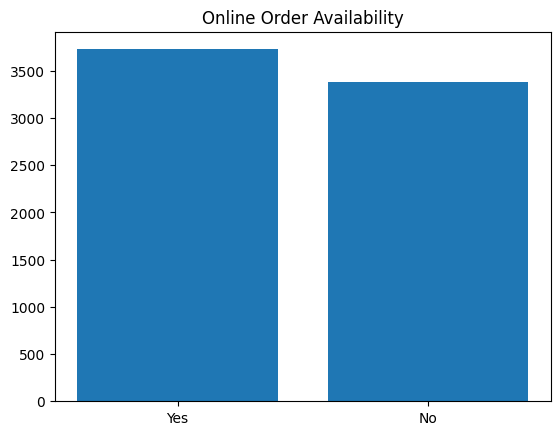

In [9]:
order_count = df['online_order'].value_counts()

import matplotlib.pyplot as plt

plt.bar(order_count.index, order_count.values)
plt.title("Online Order Availability")
plt.show()

Task 9: Table Booking Analysis

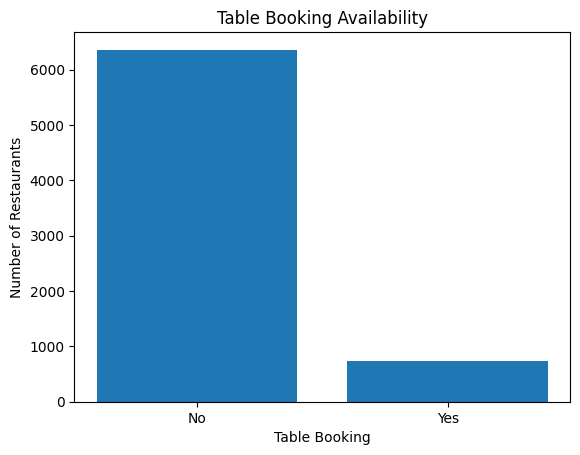

In [10]:
booking_count = df['table booking'].value_counts()

import matplotlib.pyplot as plt

plt.bar(booking_count.index, booking_count.values)

plt.title("Table Booking Availability")

plt.xlabel("Table Booking")

plt.ylabel("Number of Restaurants")

plt.show()

Task 10: Rating Distribution

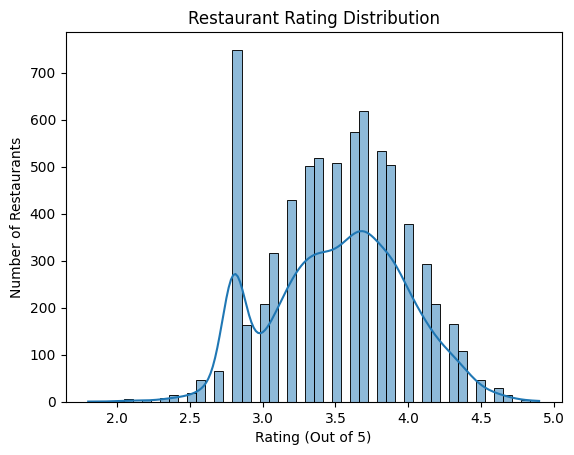

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['rate (out of 5)'], kde=True)

plt.title("Restaurant Rating Distribution")

plt.xlabel("Rating (Out of 5)")

plt.ylabel("Number of Restaurants")

plt.show()

Task 11: Cost Analysis

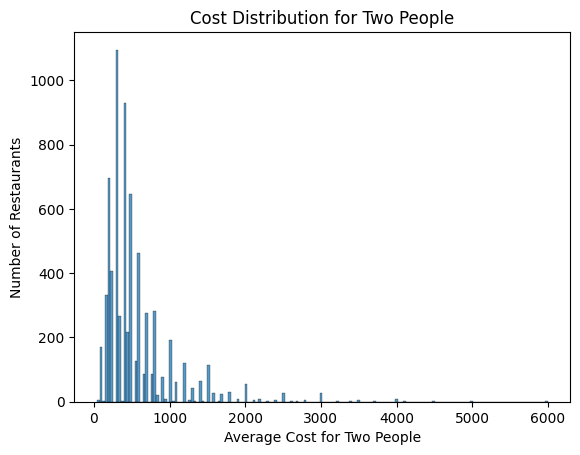

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['avg cost (two people)'])

plt.title("Cost Distribution for Two People")

plt.xlabel("Average Cost for Two People")

plt.ylabel("Number of Restaurants")

plt.show()

Task 12: Popular Cuisines

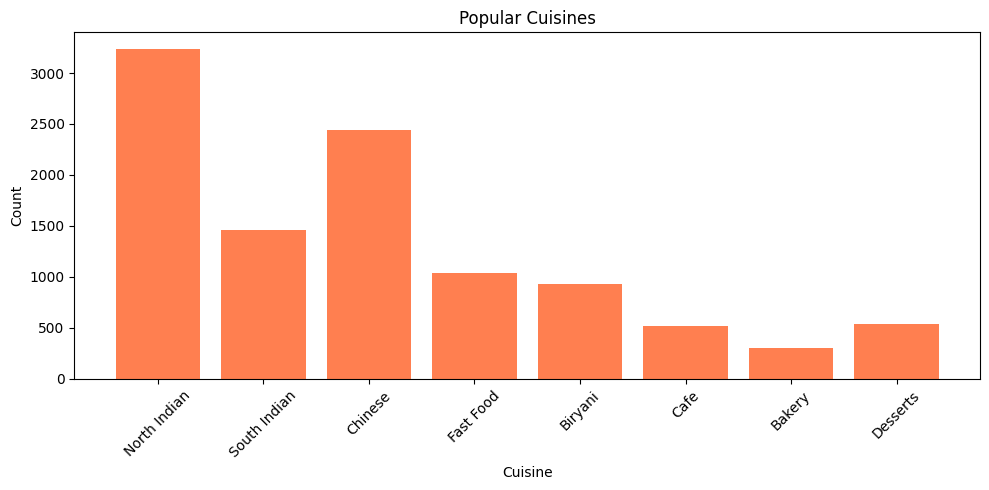

In [25]:
import matplotlib.pyplot as plt

cuisine_keywords = ['North Indian', 'South Indian', 'Chinese', 'Fast Food', 'Biryani', 'Cafe', 'Bakery', 'Desserts']

cuisine_counts = {c: df['cuisines type'].str.contains(c, case=False).sum() for c in cuisine_keywords}

plt.figure(figsize=(10,5))
plt.bar(cuisine_counts.keys(), cuisine_counts.values(), color='coral')
plt.title('Popular Cuisines')
plt.xlabel('Cuisine')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Task 13: Online Orders vs Ratings

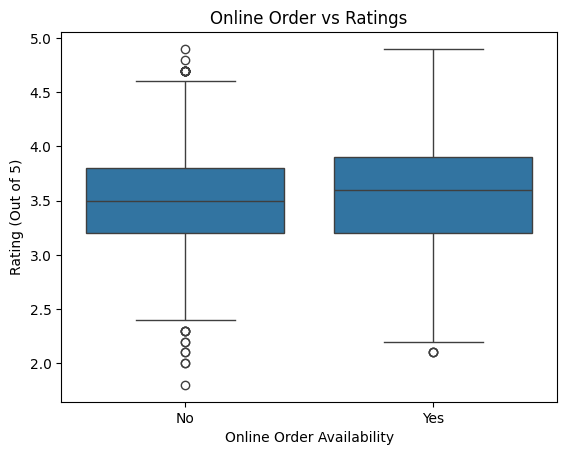

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x='online_order', y='rate (out of 5)', data=df)

plt.title("Online Order vs Ratings")

plt.xlabel("Online Order Availability")

plt.ylabel("Rating (Out of 5)")

plt.show()

Task 14: Cost vs Rating

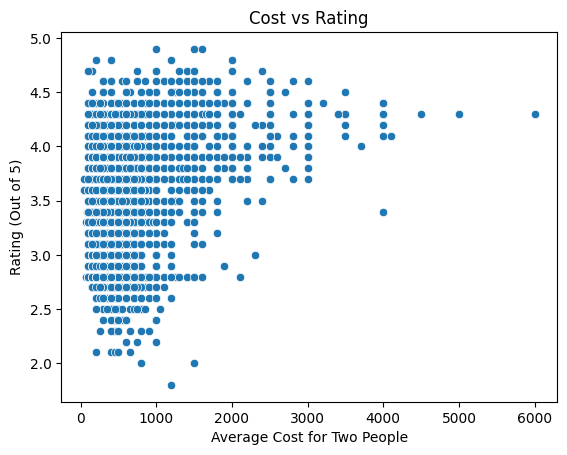

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(x='avg cost (two people)', y='rate (out of 5)', data=df)

plt.title("Cost vs Rating")

plt.xlabel("Average Cost for Two People")

plt.ylabel("Rating (Out of 5)")

plt.show()

Task 15: Top Locations with Restaurants

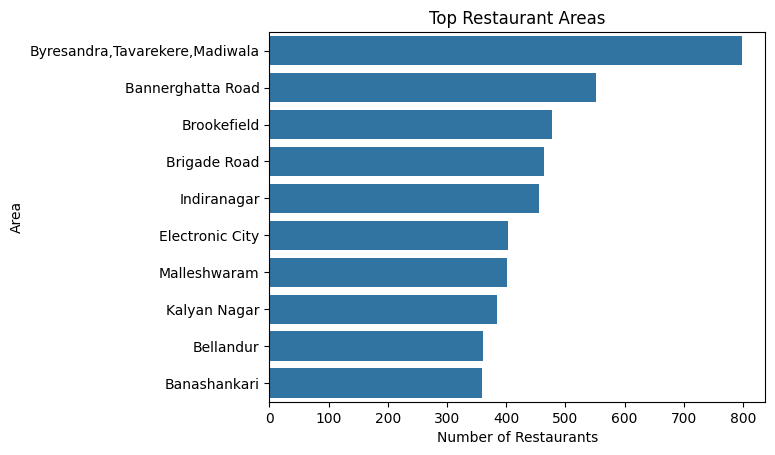

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

top_locations = df['area'].value_counts().head(10)

sns.barplot(x=top_locations.values, y=top_locations.index)

plt.title("Top Restaurant Areas")

plt.xlabel("Number of Restaurants")

plt.ylabel("Area")

plt.show()

Task 16: Bivariate Analysis

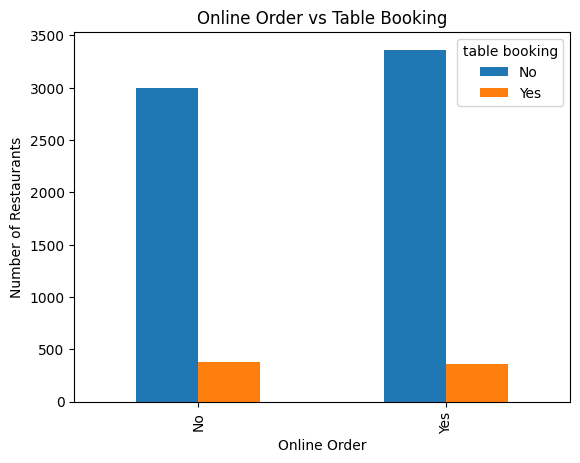

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

pd.crosstab(df['online_order'], df['table booking']).plot(kind='bar')

plt.title("Online Order vs Table Booking")

plt.xlabel("Online Order")

plt.ylabel("Number of Restaurants")

plt.show()

Task 17: Multivariate Analysis

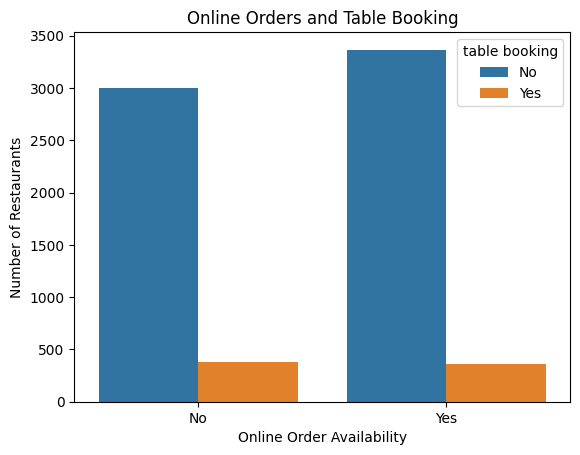

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='online_order', hue='table booking', data=df)

plt.title("Online Orders and Table Booking")

plt.xlabel("Online Order Availability")

plt.ylabel("Number of Restaurants")

plt.show()

Task 18: Correlation Matrix

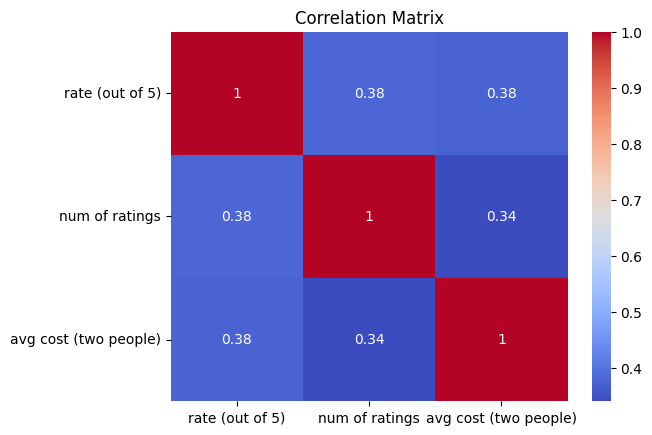

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Matrix")

plt.show()

Task 19: Dataset Preparation for ML

In [20]:
from sklearn.model_selection import train_test_split

X = df[['avg cost (two people)']]
y = df['online_order']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Dataset successfully split into training and testing sets.")

Dataset successfully split into training and testing sets.


Task 20: Machine Learning Classification

In [21]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully.")

# Make predictions
pred = model.predict(X_test)

print("Prediction completed.")

print("First 10 predictions:", pred[:10])

Model training completed successfully.
Prediction completed.
First 10 predictions: ['No' 'No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes']


Task 21: Model Evaluation (Accuracy)

In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, pred)

print("Model Accuracy:", accuracy)
print("The Decision Tree model successfully predicted online order availability.")

Model Accuracy: 0.6101337086558761
The Decision Tree model successfully predicted online order availability.


Task 22: Mean Absolute Error

In [23]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test.astype('category').cat.codes,
                          pd.Series(pred).astype('category').cat.codes)

print("MAE:", mae)

MAE: 0.38986629134412387


Task 23: Mean Squared Error

In [24]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test.astype('category').cat.codes,
                         pd.Series(pred).astype('category').cat.codes)

print("MSE:", mse)

MSE: 0.38986629134412387
